## Primer zadatka za kolokvijum: klasifikacija teksta

In [31]:
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn import metrics
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

import matplotlib.pyplot as plt
import seaborn as sb

import spacy

from pathlib import Path

In [2]:
RAND_STATE = 1

### Ucitavanje i priprema podataka

In [3]:
data = pd.read_csv(Path.cwd() / 'data' / 'McDonald_reviews_for_class.csv')

In [4]:
data.head(10)

,reviewer_id,store_address,rating_count,review,rating
0,4187,"724 Broadway, New York, NY 10003, United States",1.670,"They had a very limited space, but to make an ...",4
1,32761,"3501 Biscayne Blvd, Miami, FL 33137, United St...",2.810,clean restaurant customer service very good,5
2,12196,"1044 US-11, Champlain, NY 12919, United States",1.306,Fast and friendly service. Nice location.,5
3,12502,"501 W Imperial Hwy, Los Angeles, CA 90044, Uni...",2.722,Everytime I order from here something is alway...,1
4,3165,"429 7th Ave, New York, NY 10001, United States",2.052,Very fast and helpful oops and respectful,5
5,25293,"7010 Bradlick Shopping Center, Annandale, VA 2...",595.000,Good,4
6,10169,"690 Alameda St, Los Angeles, CA 90021, United ...",2.614,Gave me an uncooked Mc chicken gave me food po...,1
7,16342,"10901 Riverside Dr, North Hollywood, CA 91602,...",1.795,Claims to be 24 hours but it������������������...,1
8,22248,2476 Kal���������������,2.175,The food was hot and just as I ordered it.\nRe...,5
9,24848,"9814 International Dr, Orlando, FL 32819, Unit...",5.466,"Friendly and fast service, but could use a lit...",3


In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   reviewer_id    5000 non-null   int64  
 1   store_address  5000 non-null   str    
 2   rating_count   5000 non-null   float64
 3   review         4997 non-null   str    
 4   rating         5000 non-null   int64  
dtypes: float64(1), int64(2), str(2)
memory usage: 1.0 MB


In [6]:
data.dropna(subset='review', inplace=True)
data.reset_index(drop=True, inplace=True)
data.isna().sum()

reviewer_id      0
store_address    0
rating_count     0
review           0
rating           0
dtype: int64

In [7]:
data.rating.value_counts()

rating
5    1563
1    1369
4     827
3     756
2     482
Name: count, dtype: int64

In [9]:
def rating_to_sentiment(rating:int):
    if rating < 3: return 'negativan'
    return 'neutralan' if rating == 3 else 'pozitivan'

data['sentiment'] = data.rating.apply(rating_to_sentiment)
data.sentiment.value_counts(normalize=True)

sentiment
pozitivan    0.478287
negativan    0.370422
neutralan    0.151291
Name: proportion, dtype: float64

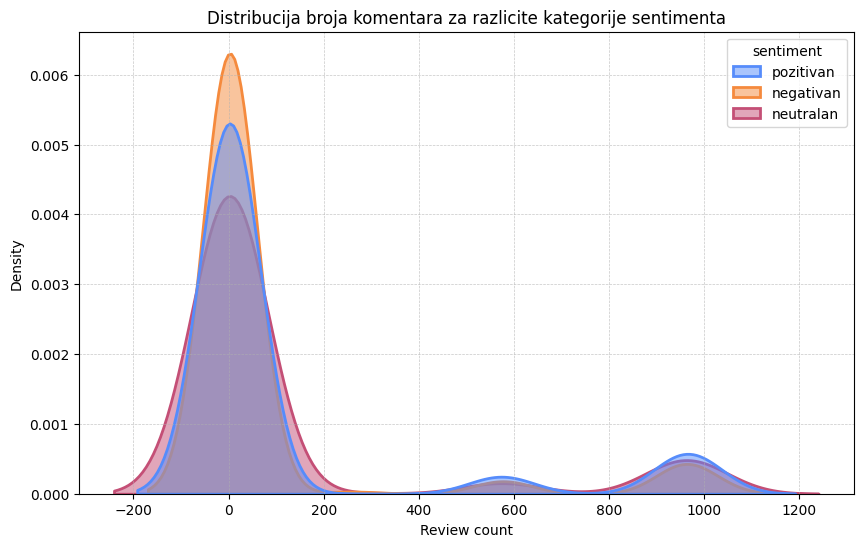

In [12]:
# NAPOMENA: primeri koda za prikaz funkcije gustine raspodele (poput koda u nastavku) i box plota ce biti raspolozivi na kolokvijumu

plt.figure(figsize=(10, 6))

sb.kdeplot(data=data,
           x='rating_count',
           hue='sentiment',
           fill=True,
           common_norm=False,
           alpha=0.5,
           linewidth=2)

plt.title('Distribucija broja komentara za razlicite kategorije sentimenta')
plt.xlabel('Review count')
plt.ylabel('Density')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


In [15]:
print(data['store_address'].nunique())
for address in data.store_address.unique():
    print(address)

37
724 Broadway, New York, NY 10003, United States
3501 Biscayne Blvd, Miami, FL 33137, United States
1044 US-11, Champlain, NY 12919, United States
501 W Imperial Hwy, Los Angeles, CA 90044, United States
429 7th Ave, New York, NY 10001, United States
7010 Bradlick Shopping Center, Annandale, VA 22003, United States
690 Alameda St, Los Angeles, CA 90021, United States
10901 Riverside Dr, North Hollywood, CA 91602, United States
2476 Kal���������������
9814 International Dr, Orlando, FL 32819, United States
72-69 Kissena Blvd, Queens, NY 11367, United States
5920 Balboa Ave, San Diego, CA 92111, United States
1415 E State Rd, Fern Park, FL 32730, United States
1916 M St NW, Washington, DC 20036, United States
5725 W Irlo Bronson Memorial Hwy, Kissimmee, FL 34746, United States
210 5th S, Salt Lake City, UT 84106, United States
490 8th Ave, New York, NY 10001, United States
1698 US-209, Brodheadsville, PA 18322, United States
By Mandalay Bay, 3999 S Las Vegas Blvd, Las Vegas, NV 89119, 

Varijabla `review_count` ima priblizno jednaku distribuciju za sve tri klase, tako da nije znacajna za kreiranje klasifikatora.

Varijabla `store_address` ima 37 razlicitih vrednosti i nije pogodna za ukljucivanje kroz one-hot-encoding (unela bi puno novih binarnih varijabli). Moglo bi se razmotriti kreiranje nove varijable kroz, na primer, ekstrakciju grada u kome se objekat nalazi (u razlicitim gradovima moze biti razlicit kvalitet prostora i usluge), ali ce ovde fokus biti na rad sa tekstom.

Konacno `reviewer_id` je obican redni broj, tako da je nebitan za klasifikaciju.

Tako da se kao ulazna varijabla zadrzava samo `review`.

In [13]:
data_sub = data[['review', 'sentiment']]
data_sub.info()

<class 'pandas.DataFrame'>
Index: 4997 entries, 0 to 4999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     4997 non-null   str  
 1   sentiment  4997 non-null   str  
dtypes: str(2)
memory usage: 762.8 KB


#### Transformacija teksta primenom Vector Space Modela

In [29]:
nlp_pipe = spacy.load('en_core_web_sm', disable=['parser','ner'])

In [18]:
def spacy_preprocessing(doc):
    tokens = nlp_pipe(doc)
    tokens = [token for token in tokens if (not token.is_punct) and (not token.is_space) and (not token.like_num) and (not token.like_url)]
    tokens = [token for token in tokens if (not token.is_stop) or (token.lemma_.lower() == 'not')]
    words = [token.lemma_.lower() for token in tokens]
    return words

def create_tfidf_vectoriser(ngrams=(1,2), max_features=-1):

    tfidf_vectorizer = TfidfVectorizer(
        tokenizer = spacy_preprocessing,
        token_pattern=None,
        ngram_range = ngrams,
        max_features=max_features if max_features > 0 else None)

    return tfidf_vectorizer

#### Kreiranje i treniranje klasifikacionog pipeline-a

In [24]:
X = data_sub['review']
y = data_sub.sentiment.values

y_encodings, y_levels = pd.factorize(y)

X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y_encodings,
                                                    test_size = 0.2,
                                                    random_state = RAND_STATE,
                                                    stratify=y_encodings)

In [55]:
tf_idf_vectorizer = create_tfidf_vectoriser(max_features=1500)

classifier = LogisticRegression(random_state=RAND_STATE,
                                max_iter=2000)

pipe = Pipeline([('vectorizer', tf_idf_vectorizer),
                 ('classifier', classifier)])

pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('vectorizer', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",<function spa...t 0x15347be20>


In [56]:
tfidf_step = pipe.named_steps["vectorizer"]
tfidf_output = tfidf_step.transform(X)
print(len(tfidf_step.get_feature_names_out()))

1500


#### Evaluacija modela na test podacima

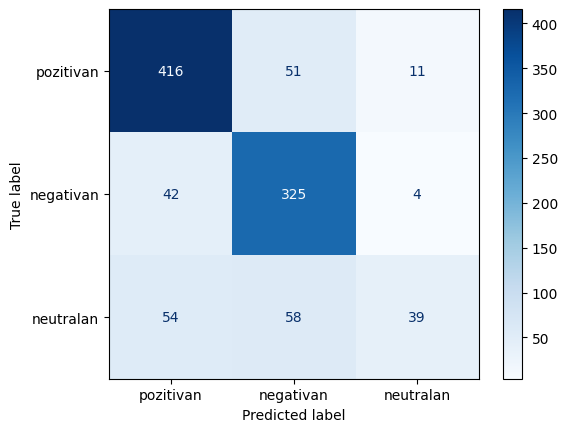

In [57]:
disp = metrics.ConfusionMatrixDisplay.from_estimator(
        pipe,
        X_test,
        y_test,
        display_labels=y_levels,
        cmap='Blues',
    )

In [58]:
predictions_1 = pipe.predict(X_test)

print(metrics.classification_report(y_true = y_test, y_pred = predictions_1, target_names=y_levels))

              precision    recall  f1-score   support

   pozitivan       0.81      0.87      0.84       478
   negativan       0.75      0.88      0.81       371
   neutralan       0.72      0.26      0.38       151

    accuracy                           0.78      1000
   macro avg       0.76      0.67      0.68      1000
weighted avg       0.78      0.78      0.76      1000



#### Interpretacija rezultata

Rezultati odrazavaju zastupljenost klasa u datom skupu podataka, tako da najvise zastipljena klasa (pozitivan) ima i najbolje rezultate, dok najmanje zastupljena klasa (neutralan) pokazuje najslabije rezultate.

Klasa 'pozitivan':
* preciznost od 0.81 ukazuje da od svih komentara za koje je predvidjeno da su pozitivnog sentimenta (416+42+54), 81% je stvarno pozitivno
* odziv od 0.87 ukazuje da od svih komentara koji su stvarno pozitivnog sentimenta (478), 87% njih je klasifikovano kao pozitivni
* F1 skor od 0.84 ukazuje na generalno dobru i balansiranu uspesnost kreiranog modela u prepoznavanju pozitivnog sentimenta

Klasa 'negativan':
* preciznost od 0.75 ukazuje da od svih komentara za koje je predvidjeno da su negativnog sentimenta (58+325+51), 75% je stvarno negativno
* odziv od 0.88 ukazuje da od svih komentara koji su stvarno negativnog sentimenta (371), 88% njih je klasifikovano kao negativno
* F1 skor od 0.81 ukazuje na generalno dobru i balansiranu uspesnost kreiranog modela u prepoznavanju negativnog sentimenta

Klasa 'neutralan':
* preciznost od 0.72 ukazuje da od svih komentara za koje je predvidjeno da su neutralnog sentimenta (39+4+11), 72% je stvarno neutralno
* odziv od 0.26 ukazuje da od svih komentara koji su stvarno neutralnog sentimenta (151), svega 26% njih je klasifikovano kao neutralni; preostali stvarno neutralni komentari su gotovo podjednako oznaceni kao pozitivni (54) i negativni (58)
* F1 skor od 0.38 ukazuje na generalno vrlo slabu i nebalansiranu uspesnost kreiranog modela u prepoznavanju neutralnog sentimenta

Posmatrano na nivou svih klasa:
* makro prosek (macro avg) F1 metrike od 0.68 ukazuje na slabu sposobnost modela da razlikuje sentiment komentara korisnika
* otezani prosek (weighted avg) F1 metrike od 0.76 ukazuje na relativno dobru sposobnost modela da prepozna dominantan sentiment, posebno pozitivan sentiment


#### Podesavanje hiperparametara

Hiperparamteri koji se najcesce podesavaju pri radu sa TF-IDF vektorima tj TfIdfVectoriser klasom su:
* `min_df` - min broj dokumenata u kojima je potrebno da se ngram pojavi da bi bio ukljucen u skup atributa
* `max_df` - max broj dokumenata u kojima se moze ngram naci da bi bio ukljucen u skup atributa
* `ngram_range` - ngrami koji ce biti razmotreni za kreiranje skupa atribita
* `max_features` - max broj atributa koji ce biti selektovani, nakon sortiranja po TF-IDF vrednosti

U slucaju klase LogisticRegression, postoji nekoliko znacajnih hiperparametara, medju kojima se posebno istice hiperaparametar C kojim se odredjuje intenzitet regularizacije modela: male vrednosti za C vode jacoj regularizaciji i povecavaju sanse za underfitting; vece vrednosti za C vode slabijoj regularizaciji i mogu da vode ka overfitting-u.

In [59]:
%%time

# namerno se zadaje mali prostor pretrazivanja kako finetuning ne bi previse dugo trajao
param_grid = {
    'vectorizer__max_features': [500, 1000],
    'classifier__C': np.logspace(-3, 3, 3)
}

random_search = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    scoring='f1_macro',
    verbose=2
)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
[CV] END ..classifier__C=0.001, vectorizer__max_features=500; total time=  10.8s
[CV] END ..classifier__C=0.001, vectorizer__max_features=500; total time=  10.8s
[CV] END ..classifier__C=0.001, vectorizer__max_features=500; total time=  10.8s
[CV] END ..classifier__C=0.001, vectorizer__max_features=500; total time=  10.8s
[CV] END ..classifier__C=0.001, vectorizer__max_features=500; total time=  10.8s
[CV] END .classifier__C=0.001, vectorizer__max_features=1000; total time=  10.9s
[CV] END .classifier__C=0.001, vectorizer__max_features=1000; total time=  10.8s
[CV] END .classifier__C=0.001, vectorizer__max_features=1000; total time=  10.9s
[CV] END .classifier__C=0.001, vectorizer__max_features=1000; total time=  11.7s
[CV] END .classifier__C=0.001, vectorizer__max_features=1000; total time=  11.6s
[CV] END ....classifier__C=1.0, vectorizer__max_features=500; total time=  13.1s
[CV] END ....classifier__C=1.0, vectorizer__max_f

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...om_state=1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': array([1.e-03...e+00, 1.e+03]), 'vectorizer__max_features': [500, 1000]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displaye

In [60]:
print("Best Hyperparameters Found:")
for param, value in random_search.best_params_.items():
    print(f"  {param}: {value}")

print(f"\nBest CV Macro F1: {random_search.best_score_:.4f}")

Best Hyperparameters Found:
  classifier__C: 1.0
  vectorizer__max_features: 1000

Best CV Macro F1: 0.6814


In [61]:
best_max_feat = random_search.best_params_['vectorizer__max_features']
best_C = random_search.best_params_['classifier__C']

pipe.set_params(vectorizer__max_features=best_max_feat,
                classifier__C=best_C)
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('vectorizer', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",<function spa...t 0x15347be20>


#### Predvidjanje i evaluacione metrike na podesenom modelu

In [62]:
predictions_2 = pipe.predict(X_test)

print(metrics.classification_report(y_true=y_test, y_pred=predictions_2, target_names=y_levels))

              precision    recall  f1-score   support

   pozitivan       0.81      0.87      0.84       478
   negativan       0.75      0.88      0.81       371
   neutralan       0.74      0.26      0.39       151

    accuracy                           0.78      1000
   macro avg       0.77      0.67      0.68      1000
weighted avg       0.78      0.78      0.76      1000



NAPOMENA: dovoljno je dati interpretaciju rezultata na jednom mestu tj za jedan model.

### Poredjenje kreiranih modela

In [63]:
## NAPOMENA: Funkcija ce biti raspoloziva na kolokvijumu
def get_model_metrics(y_true:np.ndarray, y_pred:np.ndarray, model_name:str):

    report = metrics.classification_report(y_true, y_pred, output_dict=True)

    macro_avg = report['macro avg']
    weighted_avg = report['weighted avg']

    results = {
        'Model': model_name,
        'Macro Precision': macro_avg['precision'],
        'Macro Recall': macro_avg['recall'],
        'Macro F1-Score': macro_avg['f1-score'],
        'Weighted Precision': weighted_avg['precision'],
        'Weighted Recall': weighted_avg['recall'],
        'Weighted F1-Score': weighted_avg['f1-score']
    }

    return results

In [64]:
model_predictions = {
    'TF-IDF_LR': predictions_1,
    'TF-IDF_LR_FT': predictions_2
}

all_results = list()

for model_name, model_pred in model_predictions.items():
  model_res = get_model_metrics(y_test, model_pred, model_name)
  all_results.append(model_res)

all_results_df = pd.DataFrame(all_results)
all_results_df.set_index("Model", inplace=True)
all_results_df = all_results_df.apply(lambda x: round(x, 4))

print("Poredjenje uspesnosti modela:")
print(all_results_df)

Poredjenje uspesnosti modela:
              Macro Precision  Macro Recall  Macro F1-Score  \
Model                                                         
TF-IDF_LR              0.7612        0.6682          0.6761   
TF-IDF_LR_FT           0.7668        0.6697          0.6787   

              Weighted Precision  Weighted Recall  Weighted F1-Score  
Model                                                                 
TF-IDF_LR                 0.7753             0.78             0.7587  
TF-IDF_LR_FT              0.7770             0.78             0.7592  


Model sa optimizovanim vrednostima hiperparametara nije pokazao znacajno bolje rezultate ni po jednoj od globalnih metrika (tj uprosecenih metrika svih klasa).